In [1]:
import pya
from pya import *
import SiEPIC
from SiEPIC._globals import Python_Env
from SiEPIC.scripts import connect_cell, connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC.utils import create_cell2, get_layout_variables
from SiEPIC.utils.layout import new_layout, floorplan, coupler_array
from SiEPIC.extend import to_itype
from SiEPIC.verification import layout_check
import numpy as np
from SiEPIC.scripts import connect_pins_with_waveguide, connect_cell
import os
import sys



KLayout SiEPIC-Tools version 0.5.31
SiEPIC-Tools is up to date (0.5.31 vs 0.5.31).
Version check, time: 0.12358331680297852 seconds


In [2]:

if Python_Env == 'Script':

    # Define the path to your local PDK
    path_to_pdk = r"D:\GitHub"
    # path_GitHub = r"C:\Users\gamem\OneDrive - UBC\Documents\GitHub"

    sys.path.insert(0, os.path.join(path_to_pdk, "SiEPICfab-EBeam-ZEP-PDK"))

    # Now try importing the PDK
    import SiEPICfab_EBeam_ZEP



SiEPICfab-EBeam-ZEP Python module: siepicfab_ebeam_zep, KLayout technology: SiEPICfab_EBeam_ZEP
SiEPICfab-EBeam-ZEP Python module: pymacros, v0.1.5
Libraries associated with Technology SiEPICfab_EBeam_ZEP: ['SiEPICfab_EBeam_ZEP', 'SiEPICfab_EBeam_ZEP_Beta', 'SiEPICfab_EBeam_ZEP_Superconducting', 'SiEPICfab_EBeam_ZEP_pkirwin']
Libraries associated with Technology SiEPICfab_EBeam_ZEP: ['SiEPICfab_EBeam_ZEP', 'SiEPICfab_EBeam_ZEP_Beta', 'SiEPICfab_EBeam_ZEP_Superconducting', 'SiEPICfab_EBeam_ZEP_pkirwin']


In [3]:
tech_name = 'SiEPICfab_EBeam_ZEP'  # Can change this
gclib_name = 'SiEPICfab_EBeam_ZEP_Superconducting'
lib_name = 'SiEPICfab_EBeam_ZEP_Beta'

top_cell_name = 'Test'  # Change this to the name of the top cell from the floorplan

chip_name = 'SiEPICfab_ZEP_2603'  # Change this to the name of the .oas file from the folder gds_floorplan
chip_folder = 'SiEPICfab_ZEP_SNSPDPASSIVE_202504'


chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
layout_file = os.path.join("designs", f"{top_cell_name}.oas")  # Name of the soon-to-be chip


In [4]:
"""
This script is used to extract a cell from a floorplan and save it as a GDS file.
Worry less about it, just run it and it will do the job.
"""

_, _ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
_ly.read(chip_file)
_top_cell = _ly.cell(top_cell_name)
_top_cell.write(layout_file) #save the layout to a GDS file

In [5]:
"""
This script is used to open a GDS file and display it in KLayout.
Creates a new layout and reads the GDS file the above cell made.
"""


_, ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
ly.read(layout_file)
# Access the top cell
top_cell = ly.cell(top_cell_name)

dbu = ly.dbu
wg_bend_radius = 20
              

top_cell.plot() # in the browser
top_cell.show() # in KLayout

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "open", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpxf70c5ra\\Test.gds"}


In [6]:
top_cell.bbox().width()*dbu, top_cell.bbox().height()*dbu, top_cell.bbox().right, top_cell.bbox().top # just useful to confirm the size of the cell

(500.0, 1000.0, 500000, 1000000)

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpxf70c5ra\\Test.gds"}


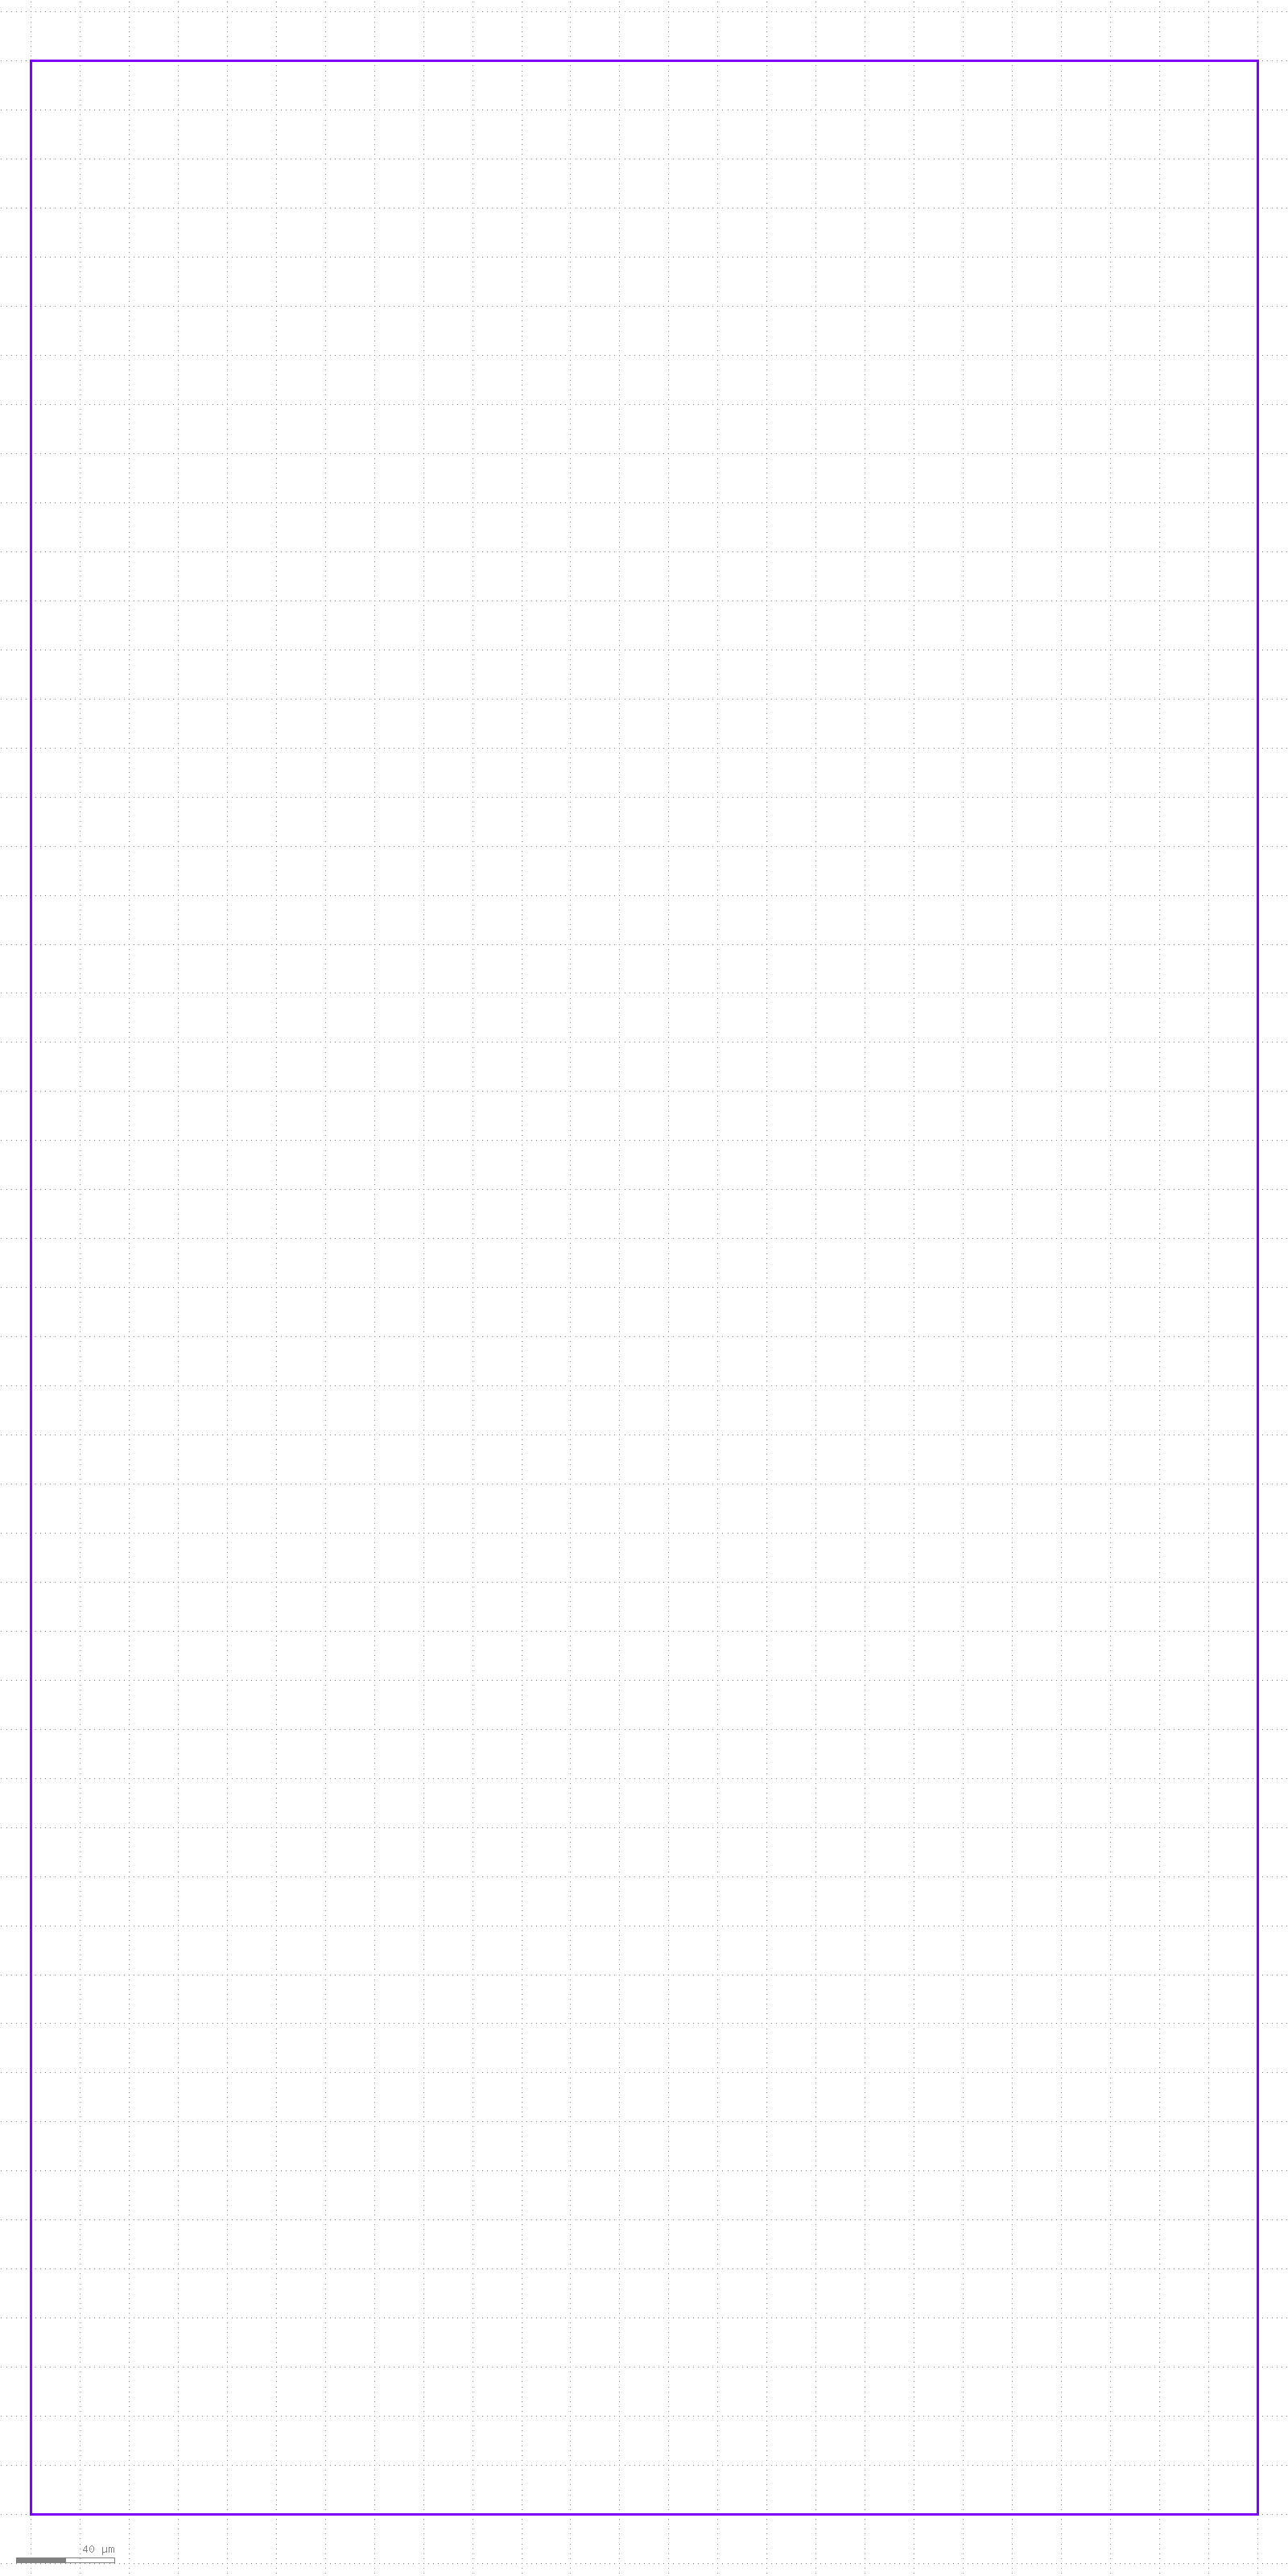

In [7]:
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

In [8]:
# ============================================================
# Global/default GC settings
# Define once and reuse in later cells
# ============================================================
GC_SETTINGS = {
    "gc_cell_name": "SiEPICfab_1550TE",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 2,
}
WG_SETTINGS = {
    "wg_type": "Strip TE 1550 nm, w=500 nm (core-clad)",
}

In [9]:
# import numpy as np
# from pya import Trans, CellInstArray

def ArbSplitter_single(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="cellname",
    device_label="opt_in_TE_1550_device",
    xmax=None,
    num_gc=None,
    device_cell_name="y_d8_split9901",
    device_library=lib_name,
    device_params=None,
    device_rotation=Trans.R0,
    device_x=None,
    device_y=None,
    device_port_in="opt1",
    device_port_out="opt2",
    gc_ports=None,
    wg_type = None,
    x_spacing=20.0,
    row_spacing=None,
    routing_to_device=None,
    routing_from_device=None,
):
    """
    Generic placement function for:
        GC array -> routing -> device -> routing

    Notes
    -----
    1. GC information is taken from the global GC_SETTINGS dictionary.
    2. This function assumes the device has optical ports such as opt1, opt2.
    3. The first and last GC are used for input/output by default.
    """

    global GC_SETTINGS, WG_SETTINGS

    if device_params is None:
        device_params = {}

    # if gc_ports is None:
    #     gc_ports = ["opt1", "opt1"]

    if routing_to_device is None:
        routing_to_device = []

    if routing_from_device is None:
        routing_from_device = []

    # Use global GC settings
    gc_cell_name = GC_SETTINGS["gc_cell_name"]
    gc_library = GC_SETTINGS["gc_library"]
    gc_pitch = GC_SETTINGS["gc_pitch"]
    label_location = GC_SETTINGS["label_location"]


    if num_gc is None:
        num_gc = GC_SETTINGS["default_num_gc"]
    gc_ports = ["opt1"] * num_gc
    
    if wg_type is None:
        wg_type = WG_SETTINGS["wg_type"]

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    # --------------------------------------------------------
    # Create new cell
    # --------------------------------------------------------
    cell = ly.create_cell(cellname)
    top_cell.insert(CellInstArray(cell.cell_index(), Trans(Trans.R0, 0, 0)))

    # --------------------------------------------------------
    # Load GC cell
    # --------------------------------------------------------
    cell_gc = create_cell2(ly, gc_cell_name, gc_library)

    # --------------------------------------------------------
    # Auto place first device near top-left
    # --------------------------------------------------------
    if x_pos_GC == 0 and y_pos_GC == top_cell.bbox().height() * dbu:
        x_pos_GC = int(cell_gc.bbox().width() * dbu)
        y_pos_GC -= int((num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2)

    # --------------------------------------------------------
    # Place GC array
    # --------------------------------------------------------
    inst_GCs = coupler_array(
        cell,
        cell_name=gc_cell_name,
        cell_library=gc_library,
        x_offset=x_pos_GC / dbu,
        y_offset=y_pos_GC / dbu,
        label=device_label,
        label_location=label_location,
        count=num_gc,
    )

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2.")

    # --------------------------------------------------------
    # Create / load device cell
    # If device_params is given, treat as PCell
    # Otherwise load as normal library cell
    # --------------------------------------------------------
    if device_params:
        cell_device = ly.create_cell(
            device_cell_name,
            device_library,
            device_params
        )
    else:
        cell_device = create_cell2(ly, device_cell_name, device_library)

    if cell_device is None:
        raise ValueError(
            f"Could not create/load device cell: "
            f"name='{device_cell_name}', library='{device_library}', params={device_params}"
        )

    # --------------------------------------------------------
    # Default device position
    # --------------------------------------------------------
    if device_x is None:
        device_x = inst_GCs[1].bbox().right * dbu + 4 * wg_bend_radius

    if device_y is None:
        device_y = inst_GCs[1].bbox().center().y * dbu#y_pos_GC - 0.5 * gc_pitch

    gc1 = inst_GCs[1]

    # print("left   =", gc1.bbox().left * dbu)
    # print("right  =", gc1.bbox().right * dbu)
    # print("bottom =", gc1.bbox().bottom * dbu)
    # print("top    =", gc1.bbox().top * dbu)

    # print("center x =", gc1.bbox().center().x * dbu)
    # print("center y =", gc1.bbox().center().y * dbu)

    t_dev = Trans(
        device_rotation,
        device_x / dbu,
        device_y / dbu
    )
    # inst_device = cell.insert(CellInstArray(cell_device.cell_index(), t_dev))

    inst_device = connect_cell(inst_GCs[1], "opt1", cell_device, "opt1",translation=device_rotation)
    inst_device.transform(Trans(50/dbu,0))
    # --------------------------------------------------------
    # Route GC[1] to device input
    # --------------------------------------------------------
    connect_pins_with_waveguide(
        inst_GCs[3], gc_ports[3],
        inst_GCs[2], gc_ports[2],
        # turtle_A=routing_to_device,
        waveguide_type=wg_type,
        # r=wg_bend_radius
    )
    
    connect_pins_with_waveguide(
        inst_GCs[1], gc_ports[1],
        inst_device, "opt1",
        # inst_GCs[1], gc_ports[1],
        # turtle_A=routing_to_device,
        waveguide_type=wg_type,
        # r=wg_bend_radius
    )

    # --------------------------------------------------------
    # Route device output to GC[-1]
    # --------------------------------------------------------
    connect_pins_with_waveguide(
        # inst_device, "opt2",
        inst_GCs[0], gc_ports[0],
        inst_device, "opt2",

        # turtle_A=routing_from_device,
        waveguide_type=wg_type,
        r=wg_bend_radius
    )

    # --------------------------------------------------------
    # Suggested next placement position
    # --------------------------------------------------------
    next_x = cell.bbox().right * dbu + x_spacing + cell_gc.bbox().width() * dbu
    next_y = y_pos_GC

    if next_x + cell.bbox().width() * dbu > xmax:
        next_x = cell_gc.bbox().width() * dbu
        next_y = cell.bbox().bottom * dbu - row_spacing - cell_gc.bbox().height() * dbu / 2

    return next_x, next_y, xmax

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpxf70c5ra\\Test.gds"}


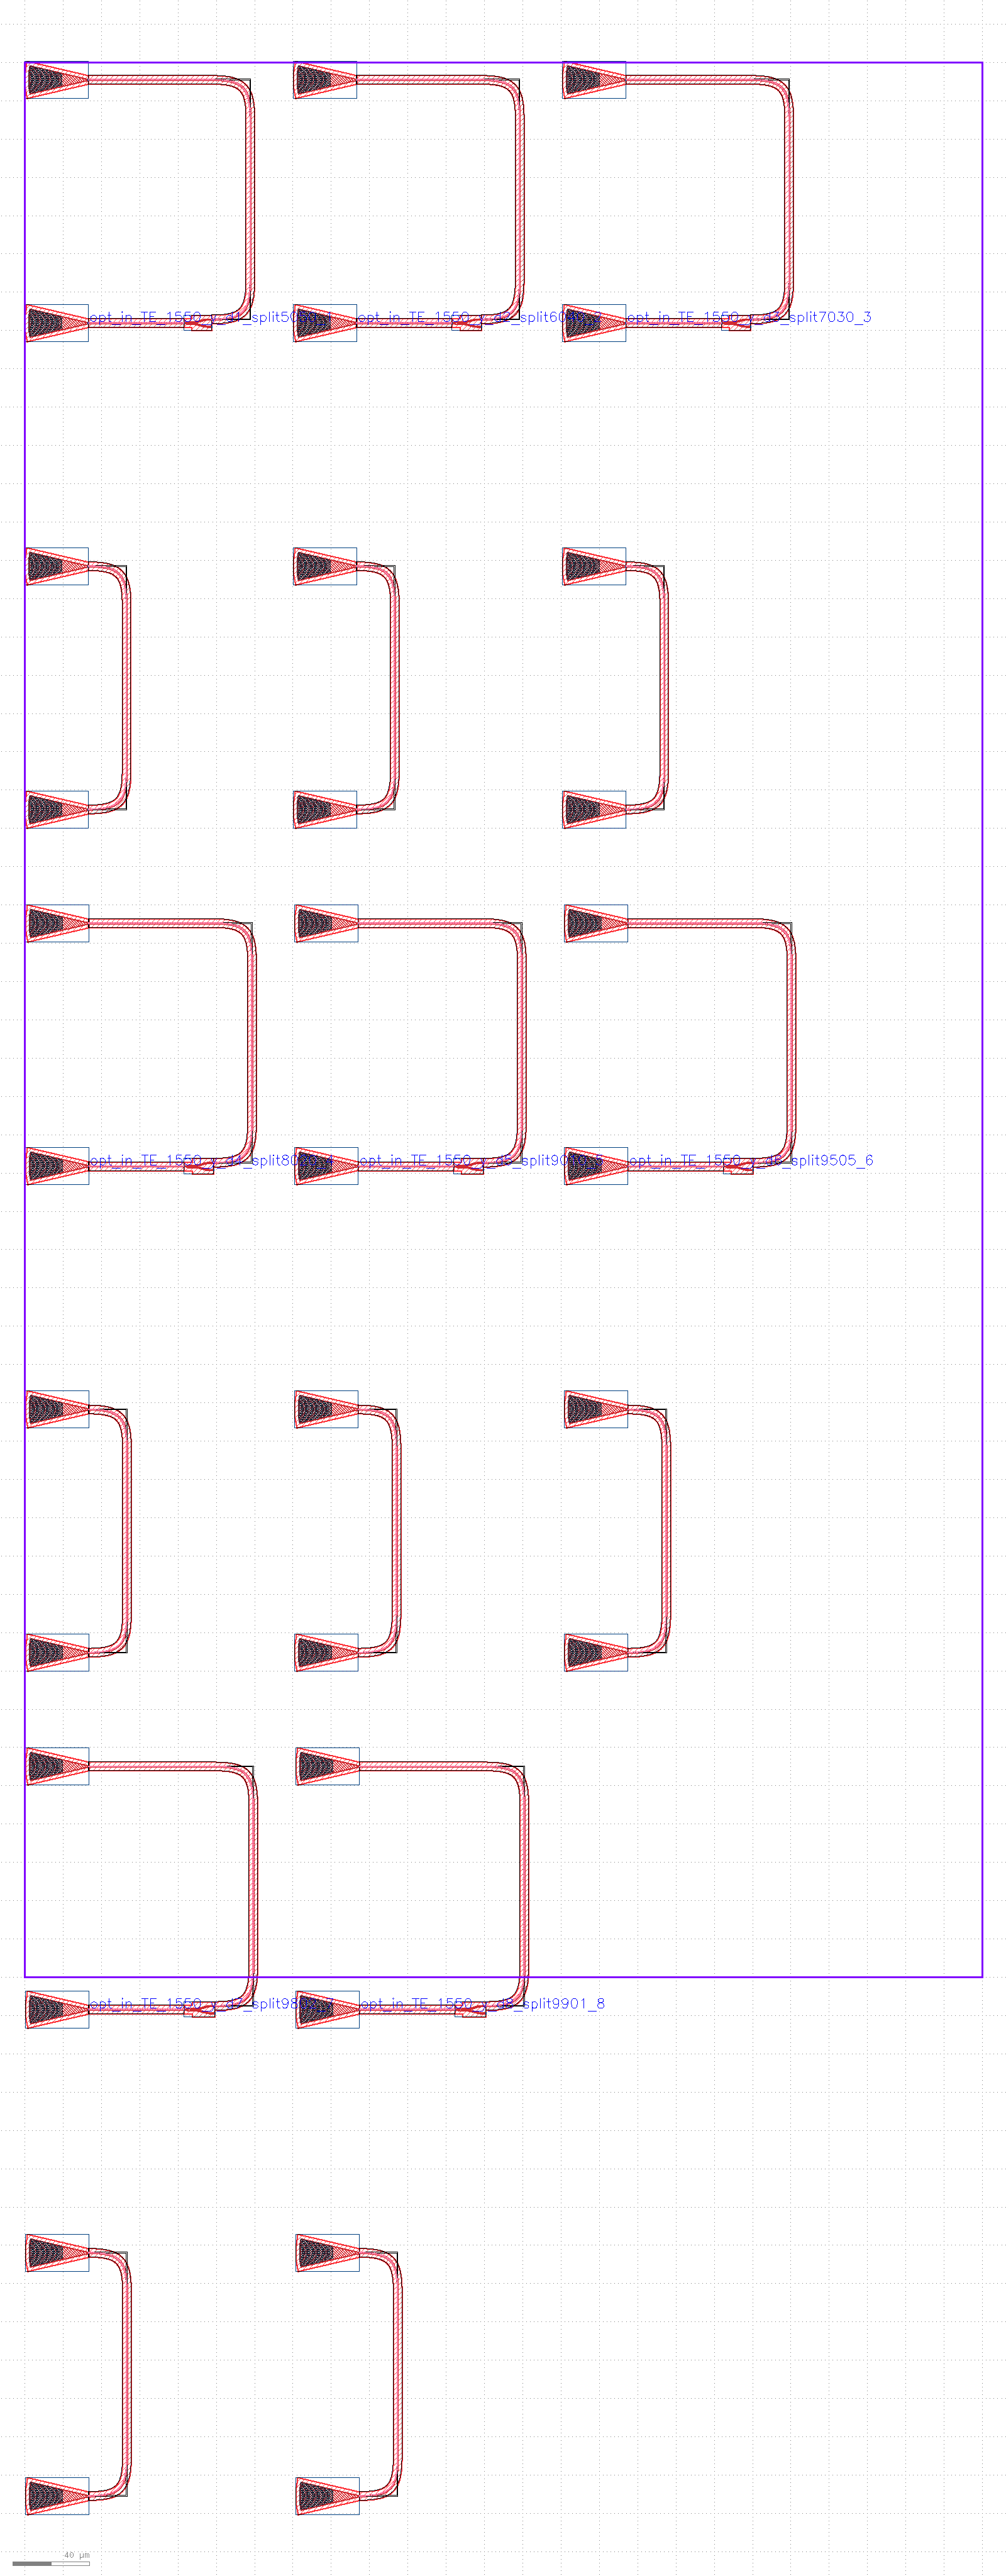

In [10]:
# Start near top-left of floorplan
x = 0
y = top_cell.bbox().height() * dbu
xmax = top_cell.bbox().width() * dbu

# Device sequence to sweep
device_cell_name_sequence = [
    "y_d1_split5050",
    "y_d2_split6040",
    "y_d3_split7030",
    "y_d4_split8020",
    "y_d5_split9010",
    "y_d6_split9505",
    "y_d7_split9802",
    "y_d8_split9901",

    # "ebeam_ybranch_te1550",
]

for i, dev_name in enumerate(device_cell_name_sequence, start=1):
    cellname = f"{dev_name}_{i}"
    label = f"opt_in_TE_1550_{dev_name}_{i}"

    x, y, xmax = ArbSplitter_single(
        x_pos_GC=x,
        y_pos_GC=y,
        cellname=cellname,
        device_label=label,
        xmax=xmax,
        num_gc=None,                  # or another number you want
        device_cell_name=dev_name,
        device_library=lib_name,
        device_params=None,
        device_rotation=pya.Trans.R0,
        device_x=None,
        device_y=None,
        device_port_in="opt1",
        device_port_out="opt2",
        gc_ports=None,
        wg_type=None,
        x_spacing=20.0,
        row_spacing=None,
        routing_to_device=None,
        routing_from_device=None,
    )

top_cell.show()
top_cell.plot()

Single device try and works

# Start near top-left of floorplan
x = 0
y = top_cell.bbox().height() * dbu
xmax = top_cell.bbox().width() * dbu

# cellname = f"ebeam_bragg_apodized_{gp_nm}_{k}"
# label = f"opt_in_TE_1550_device_Mateo_bragg_1000N_{gp_nm}nmPeriod_500nmW_20nmdW_{k}"

x, y, xmax = ArbSplitter_single(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="cellname",
    device_label="opt_in_TE_1550_device",
    xmax=None,
    num_gc=None,
    device_cell_name="y_d3_split7030",
    # device_cell_name="ebeam_ybranch_te1550",

    device_library=lib_name,
    device_params=None,
    device_rotation=pya.Trans.R0,
    device_x=None,
    device_y=None,
    device_port_in="opt1",
    device_port_out="opt2",
    gc_ports=None,
    wg_type = None,
    x_spacing=20.0,
    row_spacing=None,
    routing_to_device=None,
    routing_from_device=None,
)
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

left   = -0.14
right  = 33.05
bottom = 855.724
top    = 875.136
center x = 16.455000000000002
center y = 865.4300000000001
Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmpqt9z_3k1\\Test.gds"}


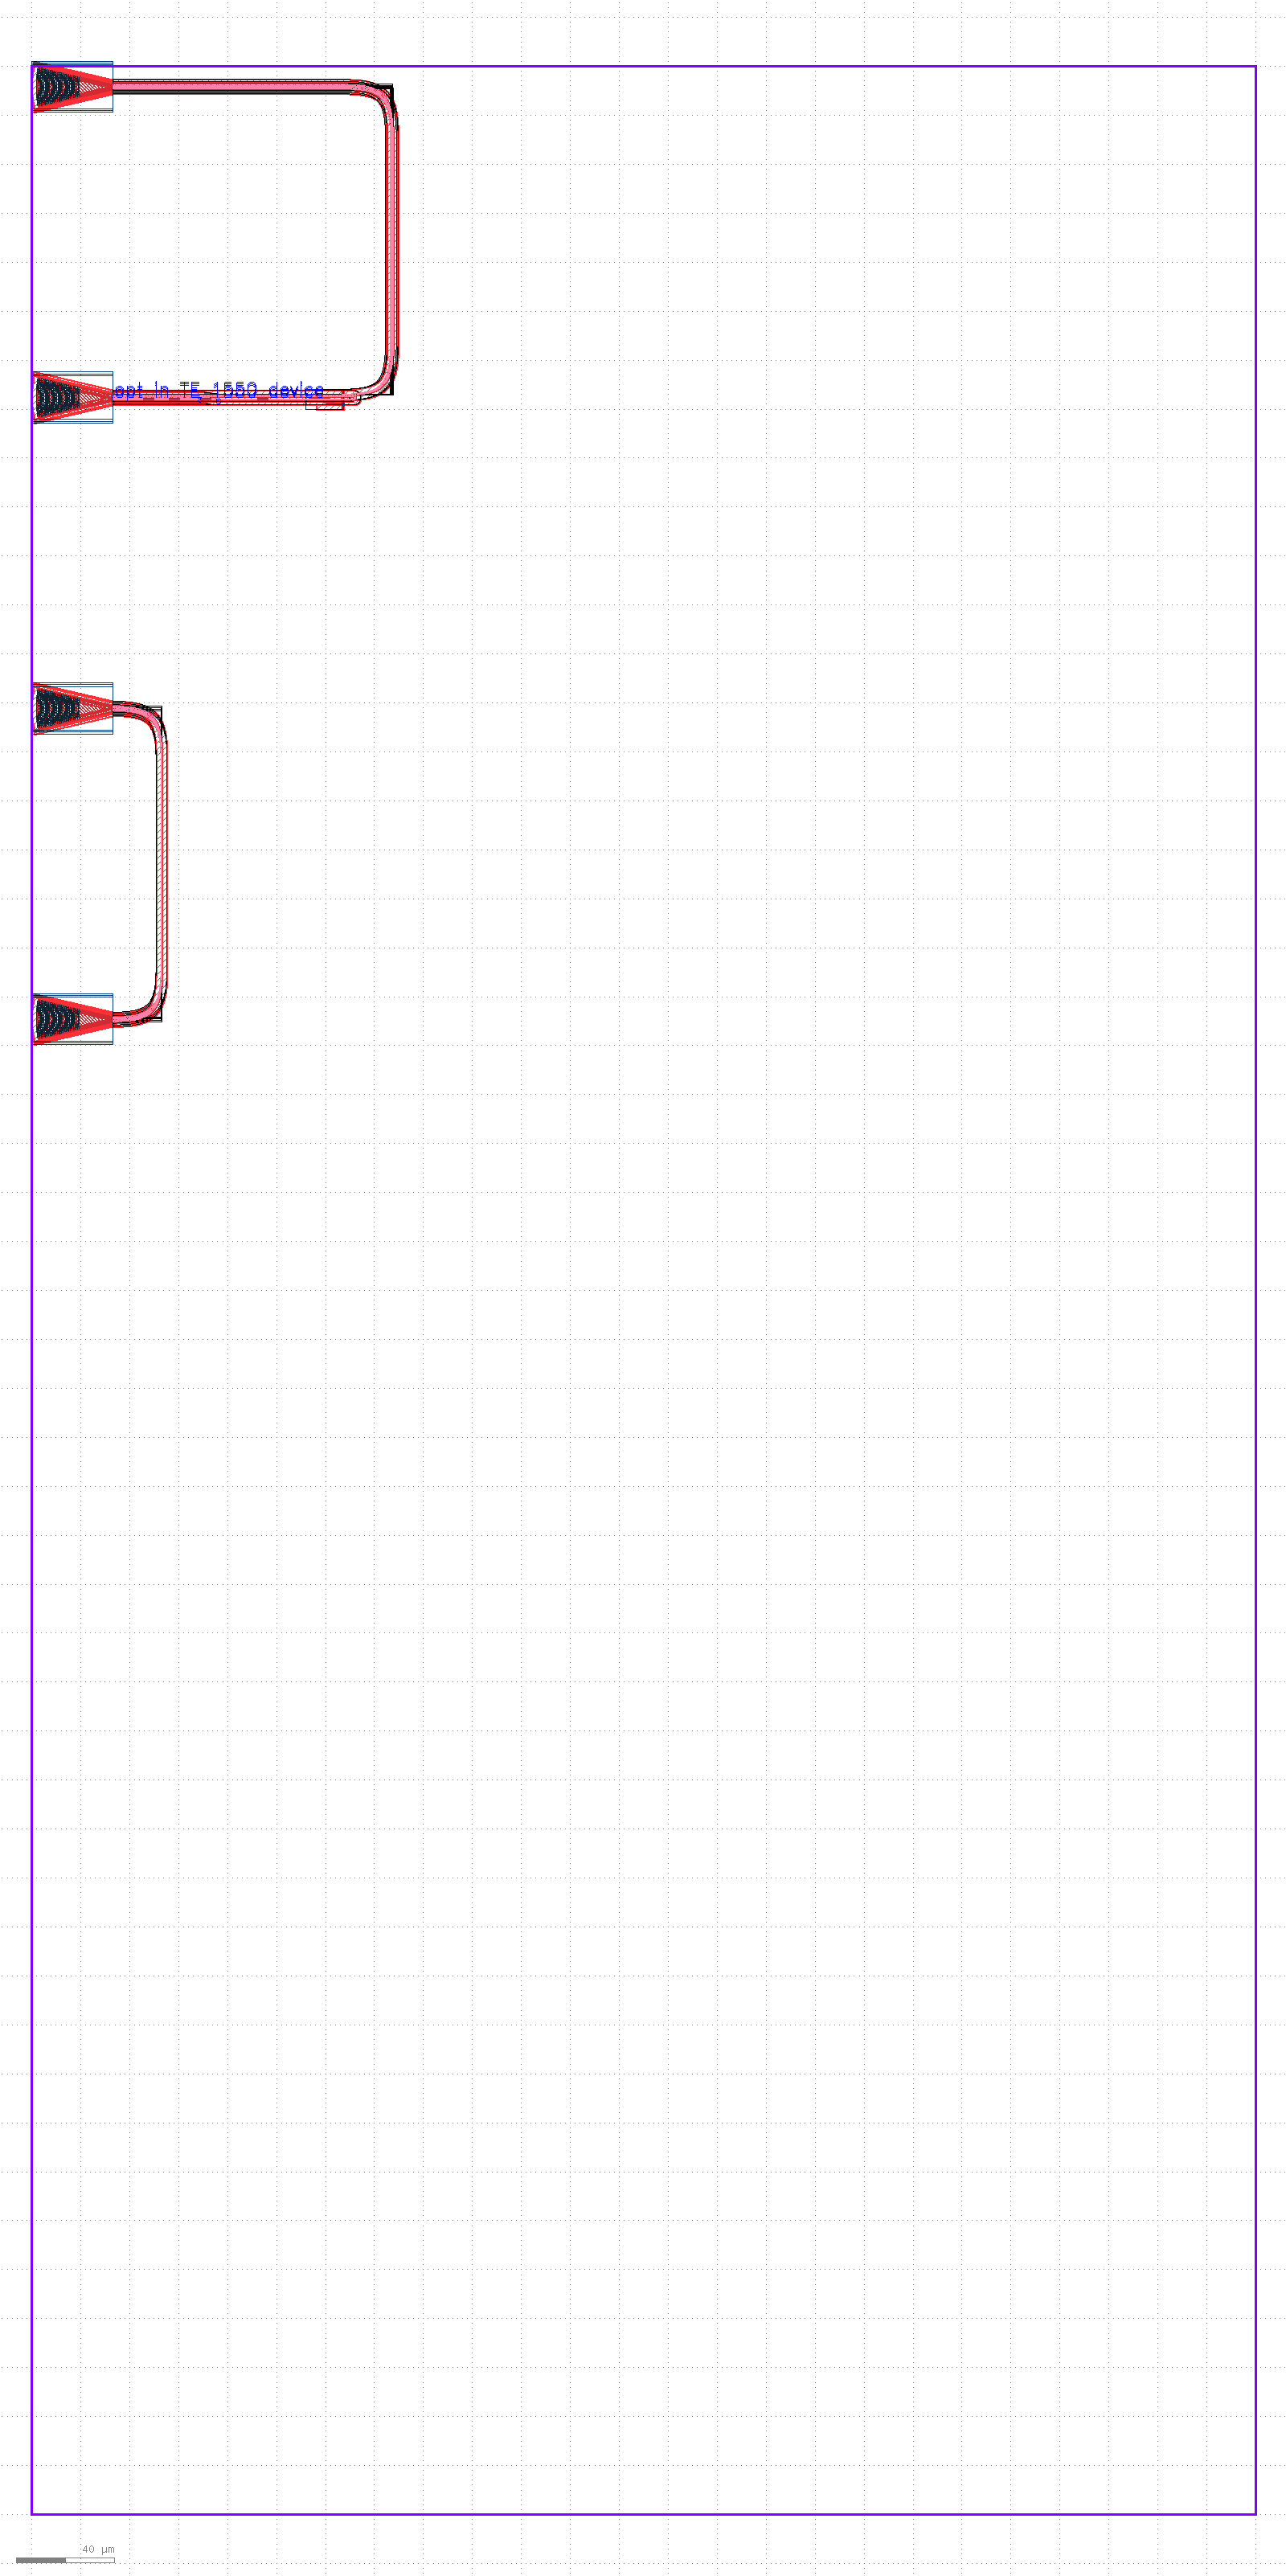

In [ ]:
# Start near top-left of floorplan
x = 0
y = top_cell.bbox().height() * dbu
xmax = top_cell.bbox().width() * dbu

# cellname = f"ebeam_bragg_apodized_{gp_nm}_{k}"
# label = f"opt_in_TE_1550_device_Mateo_bragg_1000N_{gp_nm}nmPeriod_500nmW_20nmdW_{k}"

x, y, xmax = ArbSplitter_single(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="cellname",
    device_label="opt_in_TE_1550_device",
    xmax=None,
    num_gc=None,
    device_cell_name="y_d3_split7030",
    # device_cell_name="ebeam_ybranch_te1550",

    device_library=lib_name,
    device_params=None,
    device_rotation=pya.Trans.R0,
    device_x=None,
    device_y=None,
    device_port_in="opt1",
    device_port_out="opt2",
    gc_ports=None,
    wg_type = None,
    x_spacing=20.0,
    row_spacing=None,
    routing_to_device=None,
    routing_from_device=None,
)
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

S

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmph6mku52k\\Test.gds"}


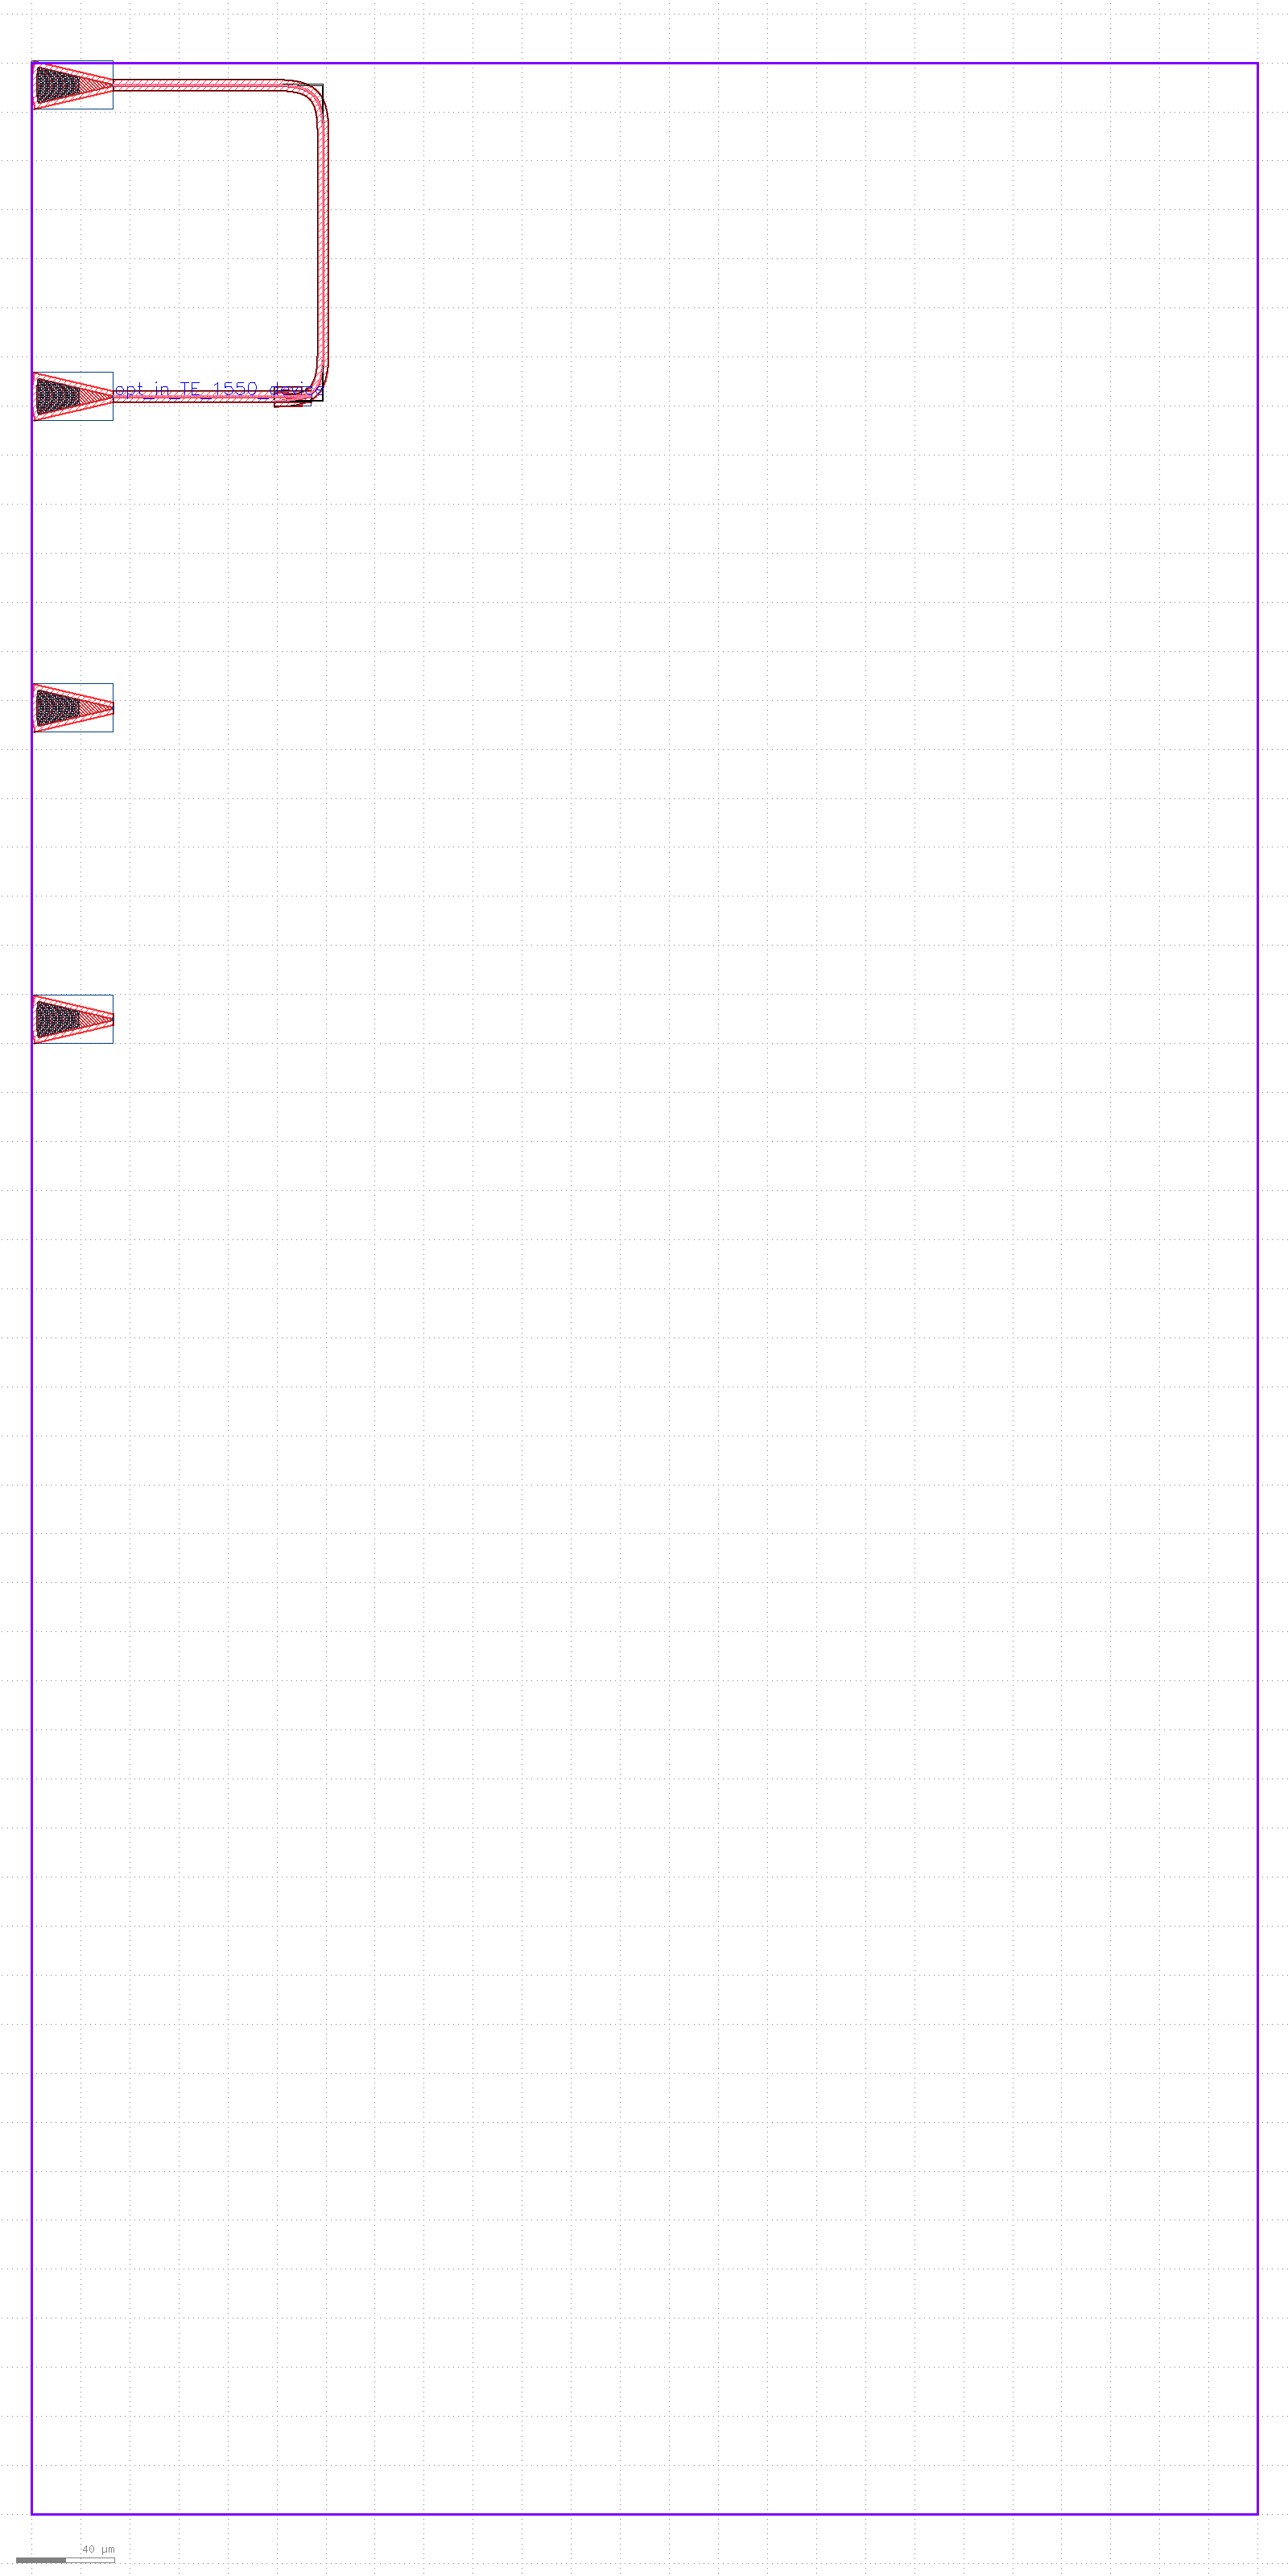

In [492]:
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

# Example of Nanobeam

In [ ]:
import numpy as np
from pya import Trans, CellInstArray

# ============================================================
# Generic function to create one GC + splitter + device layout
# ============================================================
def place_device_with_gc_array(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="device_cell",
    device_label="opt_in_TE_1550_device",
    xmax=None,
    num_gc=4,
    gc_cell_name="ebeam_GC_Air_te1550",
    gc_library=None,
    ybranch_cell_name="ebeam_ybranch_te1550",
    ybranch_library="SiEPICfab_EBeam_ZEP_Beta",
    device_cell_name="ebeam_pcell_bragg_grating",
    device_library="SiEPICfab_EBeam_ZEP_Beta",
    device_params=None,
    device_rotation=Trans.R270,
    device_offset_x=None,
    device_offset_y=None,
    wg_type="Strip TE 1550 nm, w=500 nm (core-clad)",
    wg_width=0.5,
    GC_pitch=127.0,
    row_spacing=None,
    x_spacing=20.0,
):
    """
    Generic placement function for:
        GC array -> ybranch -> device -> ybranch -> routing

    Parameters
    ----------
    x_pos_GC, y_pos_GC : float
        Starting position of the grating coupler array in microns.
        If x_pos_GC == 0 and y_pos_GC is top boundary, auto-place near top-left.

    cellname : str
        Name of the new device cell.

    device_label : str
        Label placed with the GC array.

    xmax : float
        Maximum allowed x extent in microns before wrapping to next row.

    num_gc : int
        Number of grating couplers in the array.

    gc_cell_name, gc_library : str
        GC cell information.

    ybranch_cell_name, ybranch_library : str
        Y-branch cell information.

    device_cell_name, device_library : str
        Device cell information.

    device_params : dict
        PCell parameters for the device.
        Example:
            {
                "number_of_periods": 1000,
                "grating_period": 0.32,
                "corrugation_width": 0.02
            }

    device_rotation : Trans rotation
        Rotation of the device instance, e.g. Trans.R0, Trans.R90, Trans.R180, Trans.R270.

    device_offset_x, device_offset_y : float or None
        Manual offsets for device placement relative to the first ybranch.
        Units: microns.
        If None, default placement logic will be used.

    wg_type : str
        Waveguide type name in the PDK.

    GC_pitch : float
        Pitch between GCs in microns.

    row_spacing : float or None
        Vertical spacing between wrapped rows in microns.
        If None, a reasonable value is computed automatically.

    x_spacing : float
        Horizontal spacing between neighboring devices in microns.

    Returns
    -------
    next_x, next_y, xmax : float
        Suggested coordinates for placing the next device.
    """

    if gc_library is None:
        gc_library = tech_name

    if device_params is None:
        device_params = {}

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * GC_pitch + 2 * wg_bend_radius

    # --------------------------------------------------------
    # Create top-level child cell
    # --------------------------------------------------------
    cell = ly.create_cell(cellname)
    t = Trans(Trans.R0, 0, 0)
    top_cell.insert(CellInstArray(cell.cell_index(), t))

    # --------------------------------------------------------
    # Load PDK cells
    # --------------------------------------------------------
    cell_gc = create_cell2(ly, gc_cell_name, gc_library)
    cell_ybranch = create_cell2(ly, ybranch_cell_name, ybranch_library)

    # --------------------------------------------------------
    # Auto-position starting GC array near top-left
    # --------------------------------------------------------
    if x_pos_GC == 0 and y_pos_GC == top_cell.bbox().height() * dbu:
        x_pos_GC = cell_gc.bbox().width() * dbu
        y_pos_GC -= (num_gc - 1) * GC_pitch + cell_gc.bbox().height() * dbu / 2

    # --------------------------------------------------------
    # Place GC array
    # --------------------------------------------------------
    inst_GCs = coupler_array(
        cell,
        cell_name=gc_cell_name,
        cell_library=gc_library,
        x_offset=x_pos_GC / dbu,
        y_offset=y_pos_GC / dbu,
        label=device_label,
        label_location=2,
        count=num_gc,
    )

    # Safety check
    if num_gc < 4:
        raise ValueError("num_gc must be at least 4 for the current routing scheme.")

    # --------------------------------------------------------
    # First y-branch connected to GC[1]
    # --------------------------------------------------------
    inst_ybranch = connect_cell(inst_GCs[1], "opt1", cell_ybranch, "opt1")

    # --------------------------------------------------------
    # Create generic device cell
    # --------------------------------------------------------
    cell_device = ly.create_cell(
        device_cell_name,
        device_library,
        device_params
    )

    # --------------------------------------------------------
    # Place device relative to first y-branch
    # --------------------------------------------------------
    if device_offset_x is None:
        device_offset_x = (
            inst_ybranch.bbox().right * dbu
            + wg_bend_radius
            + inst_ybranch.bbox().width() * dbu / 2
        )

    if device_offset_y is None:
        device_offset_y = (
            inst_ybranch.bbox().bottom * dbu
            - inst_ybranch.bbox().height() * dbu
            - wg_bend_radius
        )

    t_dev = Trans(
        device_rotation,
        int(device_offset_x / dbu),
        int(device_offset_y / dbu)
    )
    inst_device = cell.insert(CellInstArray(cell_device.cell_index(), t_dev))

    # --------------------------------------------------------
    # Second y-branch connected to device
    # --------------------------------------------------------
    inst_ybranch2 = connect_cell(inst_device, "opt1", cell_ybranch, "opt1")

    # --------------------------------------------------------
    # Interconnect components
    # --------------------------------------------------------
    connect_pins_with_waveguide(
        inst_GCs[0], "opt1",
        inst_ybranch2, "opt3",
        waveguide_type=wg_type,
        r=wg_bend_radius
    )

    connect_pins_with_waveguide(
        inst_ybranch, "opt2",
        inst_ybranch2, "opt2",
        waveguide_type=wg_type,
        r=wg_bend_radius
    )

    connect_pins_with_waveguide(
        inst_GCs[2], "opt1",
        inst_ybranch, "opt3",
        waveguide_type=wg_type,
        r=wg_bend_radius
    )

    connect_pins_with_waveguide(
        inst_GCs[3], "opt1",
        inst_device, "opt2",
        turtle_A=[
            wg_bend_radius, -90,
            wg_bend_radius,  90
        ],
        waveguide_type=wg_type,
        r=wg_bend_radius
    )

    # --------------------------------------------------------
    # Placement for next device
    # --------------------------------------------------------
    next_x = cell.bbox().right * dbu + x_spacing + cell_gc.bbox().width() * dbu
    next_y = y_pos_GC

    # Wrap to next row if exceeding floorplan width
    if next_x + cell.bbox().width() * dbu > xmax:
        next_x = cell_gc.bbox().width() * dbu
        next_y = cell.bbox().bottom * dbu - row_spacing - cell_gc.bbox().height() * dbu / 2

    return next_x, next_y, xmax

In [45]:
# Start near top-left of floorplan
x = 0
y = top_cell.bbox().height() * dbu
xmax = top_cell.bbox().width() * dbu

# Define grating period range (in microns)
grating_periods = np.arange(0.310, 0.340, 1e-3)

for gp in grating_periods:
    for k in range(1, 4):
        gp_nm = int(gp * 1000)

        cellname = f"ebeam_bragg_apodized_{gp_nm}_{k}"
        label = f"opt_in_TE_1550_device_Mateo_bragg_1000N_{gp_nm}nmPeriod_500nmW_20nmdW_{k}"

        x, y, xmax = place_device_with_gc_array(
            x_pos_GC=x,
            y_pos_GC=y,
            cellname=cellname,
            device_label=label,
            xmax=xmax,
            num_gc=4,
            gc_cell_name="ebeam_GC_Air_te1550",
            gc_library=tech_name,
            ybranch_cell_name="ebeam_ybranch_te1550",
            ybranch_library="SiEPICfab_EBeam_ZEP_Beta",
            device_cell_name="ebeam_pcell_bragg_grating",
            device_library="SiEPICfab_EBeam_ZEP_Beta",
            device_params={
                "number_of_periods": 1000,
                "grating_period": gp,
                "corrugation_width": 0.02
            },
            device_rotation=Trans.R270
        )

Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating
Done: ebeam_pcell_bragg_grating


In [46]:
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

KeyboardInterrupt: 